# 02 · Index benchmark: exact vs approximate, with and without quantization

**Runtime:** standard **CPU** (12.7 GB RAM, High-RAM off). Needs the outputs of `01_embed`.

| | no quantization | with quantization |
|---|---|---|
| **exact** | `flat` (baseline) | `sq8`, `pq64` |
| **approximate (IVF)** | `ivf_flat` (nprobe sweep) | `ivf_pq64` (nprobe sweep) |

Each setting is built, measured and freed before the next one, to stay inside 12.7 GB. Results go to
`results/results.csv` as they are produced. **If the runtime disconnects, rerun from the top.**
Finished settings are skipped.

`ivf_pq64` reuses the coarse centroids of `ivf_flat`. Both indexes then split the database into
exactly the same lists, so any difference between them is caused by PQ alone.

In [1]:
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "faiss-cpu==1.11.0"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")

Mounted at /content/drive


## Configuration

In [2]:
def env_str(name, default):
    return os.environ.get(name, default)


def env_int(name, default):
    return int(os.environ.get(name, default))


def env_float(name, default):
    return float(os.environ.get(name, default))


def parse_ids(spec):
    """'0-39' -> [0..39]; '0,3,5' -> [0, 3, 5]; '7' -> [7]."""
    ids = []
    for part in spec.split(","):
        part = part.strip()
        if "-" in part:
            lo, hi = part.split("-")
            ids.extend(range(int(lo), int(hi) + 1))
        elif part:
            ids.append(int(part))
    return ids


LAB2_ROOT = env_str("LAB2_ROOT", "/content/drive/MyDrive/cap6938-hw2")
LAB2_TMP = env_str("LAB2_TMP", "/content/tmp")                            # local disk, for measuring index size
LAB2_SEED = env_int("LAB2_SEED", 42)
LAB2_TOPK = env_int("LAB2_TOPK", 10)
LAB2_NLIST = env_int("LAB2_NLIST", 4096)                                  # IVF lists, about 4*sqrt(N)
LAB2_PQ_M = env_int("LAB2_PQ_M", 64)                                      # PQ sub-quantizers (bytes per vector)
LAB2_TRAIN_SAMPLE = env_int("LAB2_TRAIN_SAMPLE", 200000)                  # vectors used to train IVF/PQ/SQ
LAB2_NPROBE_LIST = parse_ids(env_str("LAB2_NPROBE_LIST", "1,2,4,8,16,32,64,128"))
LAB2_WARMUP = env_int("LAB2_WARMUP", 50)                                  # untimed queries before timing
LAB2_THREADS = env_int("LAB2_THREADS", os.cpu_count() or 1)               # FAISS OpenMP threads
LAB2_OPERATING_NPROBE = env_int("LAB2_OPERATING_NPROBE", 16)              # nprobe shown in the summary table
LAB2_SETTINGS = env_str("LAB2_SETTINGS", "flat,sq8,pq64,ivf_flat,ivf_pq64").split(",")
LAB2_FORCE = env_int("LAB2_FORCE", 0)                                     # 1 re-runs settings already in results.csv

EMB_DIR, RES_DIR = f"{LAB2_ROOT}/embeddings", f"{LAB2_ROOT}/results"
FIG_DIR = f"{RES_DIR}/figures"
for d in (RES_DIR, FIG_DIR, LAB2_TMP):
    os.makedirs(d, exist_ok=True)
assert "flat" in LAB2_SETTINGS or os.path.exists(f"{RES_DIR}/gt_flat_top{LAB2_TOPK}.npy"), \
    "flat must run first: it produces the ground truth for recall"

## Load embeddings metadata, labels and queries

In [3]:
import gc, json, time
import numpy as np
import pandas as pd
import faiss
import matplotlib.pyplot as plt

with open(f"{EMB_DIR}/manifest.json") as f:
    manifest = json.load(f)
assert "total_rows" in manifest, "run the checks cell at the end of 01_embed.ipynb first"
SHARDS = sorted(int(k) for k in manifest["shards"])
OFFSETS = {i: manifest["shards"][str(i)]["offset"] for i in SHARDS}
ROWS = {i: manifest["shards"][str(i)]["rows"] for i in SHARDS}
N, D = manifest["total_rows"], manifest["dim"]

db_labels = np.concatenate([np.load(f"{EMB_DIR}/train_{i:02d}_labels.npy") for i in SHARDS]).astype(np.int32)
Q = np.ascontiguousarray(np.load(f"{EMB_DIR}/queries.npy"), dtype=np.float32)
q_labels = np.load(f"{EMB_DIR}/queries_labels.npy").astype(np.int32)
assert len(db_labels) == N and Q.shape[1] == D

faiss.omp_set_num_threads(LAB2_THREADS)


def ram_gb():
    try:
        with open("/proc/meminfo") as f:
            return int(f.readline().split()[1]) / 1e6
    except OSError:
        return float("nan")


print(f"database {N:,} x {D} | queries {len(Q):,} | model {manifest['model']}/{manifest['pretrained']}")
print(f"faiss {faiss.__version__} | CPUs {os.cpu_count()} | FAISS threads {faiss.omp_get_max_threads()} | "
      f"RAM {ram_gb():.1f} GB")

database 1,281,167 x 768 | queries 1,000 | model ViT-L-14-quickgelu/openai
faiss 1.11.0 | CPUs 2 | FAISS threads 2 | RAM 13.3 GB


## Helpers

- **Vectors are added one shard at a time** from memory-mapped fp16 files, so a full fp32 copy of the
  database (3.9 GB for ViT-L/14) is never held next to the index.
- **Memory** is the size of the file written by `faiss.write_index`. `serialize_index` was not used
  because it builds a second copy of the index in RAM.
- **Latency** is measured one query at a time (`nq = 1`) with `time.perf_counter_ns`, after
  `LAB2_WARMUP` untimed queries. Queries are pre-embedded, so embedding time is excluded.

In [4]:
def shard_vectors():
    """Yield the database as fp32 chunks, in global-id order."""
    for i in SHARDS:
        yield np.ascontiguousarray(np.load(f"{EMB_DIR}/train_{i:02d}.npy", mmap_mode="r"), dtype=np.float32)


def training_sample():
    rng = np.random.default_rng(LAB2_SEED)
    ids = np.sort(rng.choice(N, size=min(LAB2_TRAIN_SAMPLE, N), replace=False))
    out, pos = np.empty((len(ids), D), np.float32), 0
    for i in SHARDS:
        sel = ids[(ids >= OFFSETS[i]) & (ids < OFFSETS[i] + ROWS[i])] - OFFSETS[i]
        x = np.load(f"{EMB_DIR}/train_{i:02d}.npy", mmap_mode="r")
        out[pos:pos + len(sel)] = x[sel]
        pos += len(sel)
    return out


def train_and_add(index, xt):
    t0 = time.perf_counter()
    if not index.is_trained:
        index.train(xt)
    train_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    for x in shard_vectors():
        index.add(x)
    add_s = time.perf_counter() - t0
    assert index.ntotal == N
    return train_s, add_s


def index_bytes(index, label):
    path = f"{LAB2_TMP}/{label}.faissindex"
    faiss.write_index(index, path)
    size = os.path.getsize(path)
    os.remove(path)
    return size


def run_queries(index):
    for i in range(min(LAB2_WARMUP, len(Q))):
        index.search(Q[i:i + 1], LAB2_TOPK)
    lat_ms = np.empty(len(Q))
    ids = np.empty((len(Q), LAB2_TOPK), np.int64)
    for i in range(len(Q)):
        t0 = time.perf_counter_ns()
        _, I = index.search(Q[i:i + 1], LAB2_TOPK)
        lat_ms[i] = (time.perf_counter_ns() - t0) / 1e6
        ids[i] = I[0]
    return ids, lat_ms


def precision_at_k(ids):
    """Per query: fraction of the top-k with the same class as the query (-1 = missing result = wrong)."""
    valid = ids >= 0
    same = np.zeros(ids.shape, bool)
    same[valid] = db_labels[ids[valid]] == np.broadcast_to(q_labels[:, None], ids.shape)[valid]
    return same.mean(axis=1)


def recall_at_k(ids, gt):
    """Per query: |top-k ∩ exact top-k| / k."""
    hits = ((ids[:, :, None] == gt[:, None, :]) & (ids[:, :, None] >= 0)).any(axis=2)
    return hits.sum(axis=1) / gt.shape[1]


RESULTS_CSV = f"{RES_DIR}/results.csv"
GT_PATH = f"{RES_DIR}/gt_flat_top{LAB2_TOPK}.npy"


def tag_for(label, nprobe):
    return label if nprobe is None else f"{label}_nprobe{nprobe}"


def load_results():
    return pd.read_csv(RESULTS_CSV) if os.path.exists(RESULTS_CSV) else pd.DataFrame()


def is_done(tag):
    res = load_results()
    return (not LAB2_FORCE and os.path.exists(f"{RES_DIR}/topk_{tag}.npy")
            and len(res) > 0 and tag in set(res["tag"]))


def run_setting(label, factory, build, nprobes=(None,)):
    """Build an index, measure memory, then time and score every nprobe value. Returns the index."""
    tags = [tag_for(label, p) for p in nprobes]
    if all(is_done(t) for t in tags):
        print(f"{label}: done, skipping")
        return None
    gc.collect()
    index, train_s, add_s = build()
    nbytes = index_bytes(index, label)
    print(f"{label}: train {train_s:.1f}s, add {add_s:.1f}s, {nbytes / 1e6:,.1f} MB")
    for p, tag in zip(nprobes, tags):
        if is_done(tag):
            continue
        if p is not None:
            faiss.extract_index_ivf(index).nprobe = p
        ids, lat = run_queries(index)
        if label == "flat":
            np.save(GT_PATH, ids)
        gt = np.load(GT_PATH)
        p10, r10 = precision_at_k(ids), recall_at_k(ids, gt)
        np.save(f"{RES_DIR}/topk_{tag}.npy", ids)
        np.save(f"{RES_DIR}/latency_{tag}.npy", lat)
        row = {"tag": tag, "setting": label, "factory": factory, "nprobe": p,
               "train_s": round(train_s, 2), "add_s": round(add_s, 2),
               "bytes": nbytes, "bytes_per_vec": round(nbytes / N, 1),
               "lat_median_ms": np.median(lat), "lat_p99_ms": np.percentile(lat, 99),
               "lat_mean_ms": lat.mean(), "p_at_10": p10.mean(), "recall_at_10": r10.mean(),
               "threads": faiss.omp_get_max_threads(), "n_queries": len(Q)}
        res = load_results()
        if len(res):
            res = res[res["tag"] != tag]
        pd.concat([res, pd.DataFrame([row])], ignore_index=True).to_csv(RESULTS_CSV, index=False)
        print(f"  {tag:>22}: median {row['lat_median_ms']:.3f} ms, p99 {row['lat_p99_ms']:.3f} ms, "
              f"P@10 {row['p_at_10']:.4f}, R@10 {row['recall_at_10']:.4f}")
    return index


XT = None
if any(s != "flat" for s in LAB2_SETTINGS):
    t0 = time.perf_counter()
    XT = training_sample()
    print(f"training sample {XT.shape} loaded in {time.perf_counter() - t0:.1f}s")

training sample (200000, 768) loaded in 194.5s


## Exact search: `flat`, `sq8`, `pq64`

In [5]:
def factory_builder(factory):
    def build():
        index = faiss.index_factory(D, factory, faiss.METRIC_INNER_PRODUCT)
        return (index, *train_and_add(index, XT))
    return build


EXACT = {"flat": "Flat", "sq8": "SQ8", "pq64": f"PQ{LAB2_PQ_M}"}
for label, factory in EXACT.items():
    if label in LAB2_SETTINGS:
        index = run_setting(label, factory, factory_builder(factory))
        del index
        gc.collect()

flat: train 0.0s, add 14.9s, 3,935.7 MB
                    flat: median 366.352 ms, p99 454.149 ms, P@10 0.7012, R@10 1.0000
sq8: train 0.1s, add 16.1s, 983.9 MB
                     sq8: median 216.020 ms, p99 472.058 ms, P@10 0.7006, R@10 0.9810
pq64: train 271.1s, add 87.0s, 82.8 MB
                    pq64: median 45.823 ms, p99 86.495 ms, P@10 0.6059, R@10 0.3286


## Approximate search: `ivf_flat` and `ivf_pq64`, nprobe sweep

`ivf_flat` trains the coarse quantizer with k-means. Its centroids are saved to
`results/ivf_centroids.npy` and reused by `ivf_pq64`, which only has to train the PQ codebooks.

In [6]:
CENTROIDS = f"{RES_DIR}/ivf_centroids.npy"
IVF_FLAT = f"IVF{LAB2_NLIST},Flat"
IVF_PQ = f"IVF{LAB2_NLIST},PQ{LAB2_PQ_M}"

if "ivf_flat" in LAB2_SETTINGS:
    index = run_setting("ivf_flat", IVF_FLAT, factory_builder(IVF_FLAT), LAB2_NPROBE_LIST)
    if index is not None:
        ivf = faiss.extract_index_ivf(index)
        np.save(CENTROIDS, ivf.quantizer.reconstruct_n(0, ivf.nlist))
    del index
    gc.collect()


def build_ivf_pq_shared():
    quantizer = faiss.IndexFlatIP(D)
    quantizer.add(np.load(CENTROIDS))
    index = faiss.IndexIVFPQ(quantizer, D, LAB2_NLIST, LAB2_PQ_M, 8, faiss.METRIC_INNER_PRODUCT)
    return (index, *train_and_add(index, XT))   # quantizer already holds nlist centroids: PQ-only training


if "ivf_pq64" in LAB2_SETTINGS:
    assert os.path.exists(CENTROIDS), "run ivf_flat first: ivf_pq64 reuses its centroids"
    index = run_setting("ivf_pq64", IVF_PQ + " (shared coarse centroids)", build_ivf_pq_shared,
                        LAB2_NPROBE_LIST)
    del index
    gc.collect()

ivf_flat: train 221.0s, add 150.8s, 3,958.6 MB
        ivf_flat_nprobe1: median 1.104 ms, p99 2.065 ms, P@10 0.6721, R@10 0.6288
        ivf_flat_nprobe2: median 1.213 ms, p99 1.648 ms, P@10 0.6912, R@10 0.8064
        ivf_flat_nprobe4: median 1.544 ms, p99 2.076 ms, P@10 0.7014, R@10 0.9002
        ivf_flat_nprobe8: median 2.022 ms, p99 2.718 ms, P@10 0.7020, R@10 0.9496
       ivf_flat_nprobe16: median 3.476 ms, p99 5.989 ms, P@10 0.7008, R@10 0.9754
       ivf_flat_nprobe32: median 4.936 ms, p99 6.568 ms, P@10 0.7016, R@10 0.9886
       ivf_flat_nprobe64: median 8.829 ms, p99 13.387 ms, P@10 0.7011, R@10 0.9947
      ivf_flat_nprobe128: median 15.766 ms, p99 21.732 ms, P@10 0.7009, R@10 0.9981
ivf_pq64: train 29.1s, add 215.6s, 105.6 MB
        ivf_pq64_nprobe1: median 0.868 ms, p99 1.313 ms, P@10 0.6514, R@10 0.3908
        ivf_pq64_nprobe2: median 0.916 ms, p99 1.231 ms, P@10 0.6699, R@10 0.4571
        ivf_pq64_nprobe4: median 1.024 ms, p99 1.530 ms, P@10 0.6787, R@10 0.4799
    

## Results

In [7]:
res = load_results()
show = res[["tag", "bytes", "lat_median_ms", "lat_p99_ms", "p_at_10", "recall_at_10", "train_s", "add_s"]].copy()
show["MB"] = show.pop("bytes") / 1e6
pd.set_option("display.float_format", "{:,.4f}".format)
display(show)

,tag,lat_median_ms,lat_p99_ms,p_at_10,recall_at_10,train_s,add_s,MB
0,flat,366.3520,454.1491,0.7012,1.0000,0.0000,14.9300,"3,935.7451"
1,sq8,216.0196,472.0580,0.7006,0.9810,0.0800,16.1300,983.9425
2,pq64,45.8234,86.4945,0.6059,0.3286,271.0600,87.0400,82.7812
3,ivf_flat_nprobe1,1.1036,2.0648,0.6721,0.6288,220.9900,150.8400,"3,958.6102"
4,ivf_flat_nprobe2,1.2132,1.6482,0.6912,0.8064,220.9900,150.8400,"3,958.6102"
5,ivf_flat_nprobe4,1.5443,2.0763,0.7014,0.9002,220.9900,150.8400,"3,958.6102"
6,ivf_flat_nprobe8,2.0223,2.7181,0.7020,0.9496,220.9900,150.8400,"3,958.6102"
7,ivf_flat_nprobe16,3.4759,5.9894,0.7008,0.9754,220.9900,150.8400,"3,958.6102"
8,ivf_flat_nprobe32,4.9358,6.5684,0.7016,0.9886,220.9900,150.8400,"3,958.6102"
9,ivf_flat_nprobe64,8.8286,13.3869,0.7011,0.9947,220.9900,150.8400,"3,958.6102"


In [8]:
def pick(setting, nprobe=None):
    rows = res[res["setting"] == setting]
    if nprobe is not None:
        rows = rows[rows["nprobe"] == nprobe]
    return rows.iloc[0] if len(rows) else None


summary_rows = [("exact", "no", pick("flat")), ("exact", "SQ8", pick("sq8")), ("exact", "PQ", pick("pq64")),
                (f"IVF nprobe={LAB2_OPERATING_NPROBE}", "no", pick("ivf_flat", LAB2_OPERATING_NPROBE)),
                (f"IVF nprobe={LAB2_OPERATING_NPROBE}", "PQ", pick("ivf_pq64", LAB2_OPERATING_NPROBE))]
flat_med = pick("flat")["lat_median_ms"]
summary = pd.DataFrame([{"search": s, "quantization": q, "memory_MB": r["bytes"] / 1e6,
                         "lat_median_ms": r["lat_median_ms"], "lat_p99_ms": r["lat_p99_ms"],
                         "speedup_vs_flat": flat_med / r["lat_median_ms"],
                         "P@10": r["p_at_10"], "R@10": r["recall_at_10"]}
                        for s, q, r in summary_rows if r is not None])
summary.to_csv(f"{RES_DIR}/summary.csv", index=False)
display(summary)
print(summary.to_markdown(index=False, floatfmt=".3f"))

,search,quantization,memory_MB,lat_median_ms,lat_p99_ms,speedup_vs_flat,P@10,R@10
0,exact,no,"3,935.7451",366.3520,454.1491,1.0000,0.7012,1.0000
1,exact,SQ8,983.9425,216.0196,472.0580,1.6959,0.7006,0.9810
2,exact,PQ,82.7812,45.8234,86.4945,7.9949,0.6059,0.3286
3,IVF nprobe=16,no,"3,958.6102",3.4759,5.9894,105.3982,0.7008,0.9754
4,IVF nprobe=16,PQ,105.6463,1.5177,2.0713,241.3831,0.6815,0.4922


| search        | quantization   |   memory_MB |   lat_median_ms |   lat_p99_ms |   speedup_vs_flat |   P@10 |   R@10 |
|:--------------|:---------------|------------:|----------------:|-------------:|------------------:|-------:|-------:|
| exact         | no             |    3935.745 |         366.352 |      454.149 |             1.000 |  0.701 |  1.000 |
| exact         | SQ8            |     983.942 |         216.020 |      472.058 |             1.696 |  0.701 |  0.981 |
| exact         | PQ             |      82.781 |          45.823 |       86.495 |             7.995 |  0.606 |  0.329 |
| IVF nprobe=16 | no             |    3958.610 |           3.476 |        5.989 |           105.398 |  0.701 |  0.975 |
| IVF nprobe=16 | PQ             |     105.646 |           1.518 |        2.071 |           241.383 |  0.681 |  0.492 |


### Trade-off plot

Median latency (log scale) against recall@10 and precision@10. The two IVF lines run from
nprobe = 1 (left) to the largest nprobe (right). Exact-search settings are single points.

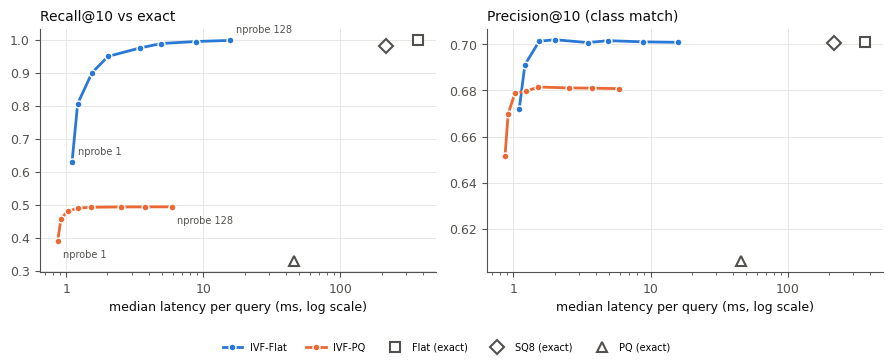

In [9]:
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SERIES = {"ivf_flat": ("#2a78d6", "IVF-Flat"), "ivf_pq64": ("#eb6834", "IVF-PQ")}
EXACT_MARKERS = {"flat": ("s", "Flat (exact)"), "sq8": ("D", "SQ8 (exact)"), "pq64": ("^", "PQ (exact)")}

from matplotlib.ticker import FuncFormatter, NullFormatter

plt.rcParams.update({"font.size": 9, "axes.edgecolor": INK_2, "axes.labelcolor": INK, "xtick.color": INK_2,
                     "ytick.color": INK_2, "axes.spines.top": False, "axes.spines.right": False})
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharex=True)
for ax, metric, name in zip(axes, ["recall_at_10", "p_at_10"], ["Recall@10 vs exact", "Precision@10 (class match)"]):
    for setting, (color, label) in SERIES.items():
        rows = res[res["setting"] == setting].sort_values("nprobe")
        if not len(rows):
            continue
        ax.plot(rows["lat_median_ms"], rows[metric], "-o", color=color, lw=2, ms=5, label=label,
                markeredgecolor="white", markeredgewidth=1)
        if metric == "recall_at_10":   # nprobe labels on the recall panel only, to avoid overlap
            dy = 6 if setting == "ivf_flat" else -12
            for _, r in rows.iloc[[0, -1]].iterrows():
                ax.annotate(f"nprobe {int(r['nprobe'])}", (r["lat_median_ms"], r[metric]), fontsize=7,
                            color=INK_2, xytext=(4, dy), textcoords="offset points")
    for setting, (marker, label) in EXACT_MARKERS.items():
        r = pick(setting)
        if r is not None:
            ax.plot(r["lat_median_ms"], r[metric], marker, color=INK_2, ms=7, label=label,
                    markerfacecolor="white", markeredgewidth=1.5)
    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel("median latency per query (ms, log scale)")
    ax.set_title(name, fontsize=10, color=INK, loc="left")
    ax.grid(True, color=GRID, lw=0.6)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=len(labels), fontsize=7, frameon=False)
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(f"{FIG_DIR}/tradeoff.png", dpi=200)
plt.show()

### Additional profiling: embedding and build cost

In [10]:
embed_s = sum(s["embed_s"] for s in manifest["shards"].values())
smoke_path = f"{EMB_DIR}/smoke_test.json"
smoke = json.load(open(smoke_path)) if os.path.exists(smoke_path) else {}
print(f"embedding: {embed_s / 3600:.2f} h for {N:,} images = {N / embed_s:,.0f} img/s "
      f"on {smoke.get('device', '?')} (GPU-only ceiling {smoke.get('gpu_only_img_per_s', float('nan')):,.0f} img/s)")
builds = res.drop_duplicates("setting")[["setting", "train_s", "add_s", "bytes_per_vec"]]
display(builds)

embedding: 0.59 h for 1,281,167 images = 603 img/s on NVIDIA A100-SXM4-40GB (GPU-only ceiling 676 img/s)


,setting,train_s,add_s,bytes_per_vec
0,flat,0.0000,14.9300,"3,072.0000"
1,sq8,0.0800,16.1300,768.0000
2,pq64,271.0600,87.0400,64.6000
3,ivf_flat,220.9900,150.8400,"3,089.8000"
11,ivf_pq64,29.1000,215.6500,82.5000
